# 05 · Emittance Measurement: quadrupole scan, and 3 methods of reconstruction

## Beam matrix and transport

At the scanned quadrupole the beam is described by
$$\Sigma_0=\varepsilon\begin{pmatrix}\beta&-\alpha\\-\alpha&\gamma\end{pmatrix},\qquad \gamma=\frac{1+\alpha^2}{\beta},\qquad \varepsilon=\sqrt{\det\Sigma_0},$$
and a linear transport $R$ to the screen gives $\Sigma_s=R\,\Sigma_0R^T$, so the measured size is
$$\sigma^2=R_{11}^2\Sigma_{11}+2R_{11}R_{12}\Sigma_{12}+R_{12}^2\Sigma_{22}.$$
Each scan setting gives one linear equation for $(\Sigma_{11},\Sigma_{12},\Sigma_{22})$, so at least **three** different settings are needed.

# The scan parabola

For a thin quadrupole $k=k_1L$ followed by a drift $L$: $R_{11}=1-Lk$, $R_{12}=L$. Then $\sigma^2(k)$ is a parabola in $k$,
$$\sigma^2(k)=a\,(k-k_w)^2+c,\qquad a=L^2\Sigma_{11},\qquad c=\frac{L^2\varepsilon^2}{\Sigma_{11}},\qquad k_w=\frac1L+\frac{\Sigma_{12}}{\Sigma_{11}},$$
which gives the classic result
$$\varepsilon=\frac{\sqrt{a\,c}}{L^2},\qquad \beta=\frac{a}{L^2\varepsilon},\qquad \alpha=-\beta\left(k_w-\frac1L\right).$$

The normalized emittance is $\varepsilon_n=\beta_{rel}\gamma_{rel}\,\varepsilon$ with the relativistic factors.

**Run:** follow [the setup guide](README.md), select the **Flight tutorials** kernel, then **Restart Kernel and Run All Cells**.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from tutorial_support import beam_matrix, scan_sizes
from emittance_measurement.EM_helpers.CheckLinearOptics import _solve_plane, _sigma2, CheckLinearOpticsUnavailable

L = 2.0
rng = np.random.default_rng(16)
truth = beam_matrix(emittance=2e-6, beta=4.0, alpha=0.8)
k = np.linspace(-0.3, 0.9, 21)
u_sigma = np.full(k.size, 8e-6)
sigma_measured = scan_sizes(k, truth, drift=L) + rng.normal(0, u_sigma)
R11, R12 = 1.0 - L * k, np.full(k.size, L)

emittance, beta, alpha, chi2, physical = _solve_plane(R11, R12, sigma_measured, u_sigma, np.ones(k.size, bool))
a, b, c0 = np.polyfit(k, sigma_measured**2, 2)
k_w = -b / (2 * a)
c = c0 - a * k_w**2
print(f'Fitter:   ε = {emittance * 1e6:.3f} µm·rad, β = {beta:.3f} m, α = {alpha:.3f}, χ²_red = {chi2:.2f}, physical = {physical}')
print(f'Parabola: ε = √(ac)/L² = {np.sqrt(a * c) / L**2 * 1e6:.3f} µm·rad, waist at k = {k_w:.3f} 1/m')
print(f'Truth:    ε = 2.000 µm·rad, β = 4.000 m, α = 0.800, waist at k = {1 / L + truth[0, 1] / truth[0, 0]:.3f} 1/m')

Fitter:   ε = 2.000 µm·rad, β = 4.005 m, α = 0.799, χ²_red = 0.99, physical = True
Parabola: ε = √(ac)/L² = 2.002 µm·rad, waist at k = 0.301 1/m
Truth:    ε = 2.000 µm·rad, β = 4.000 m, α = 0.800, waist at k = 0.300 1/m


## The fit

1. solves the linear least-squares problem for $(\Sigma_{11},\Sigma_{12},\Sigma_{22})$.
2. checks whether this result is a physical beam matrix ($\Sigma_{11},\Sigma_{22}>0$, $\det\Sigma>0$);
3. refits with the parametrization $\Sigma_{11}=a^2$, $\Sigma_{12}=ab$, $\Sigma_{22}=b^2+c^2$, which is always physical, and returns $\varepsilon=ac$, $\beta=a/c$, $\alpha=-b/c$ and the reduced $\chi^2$.

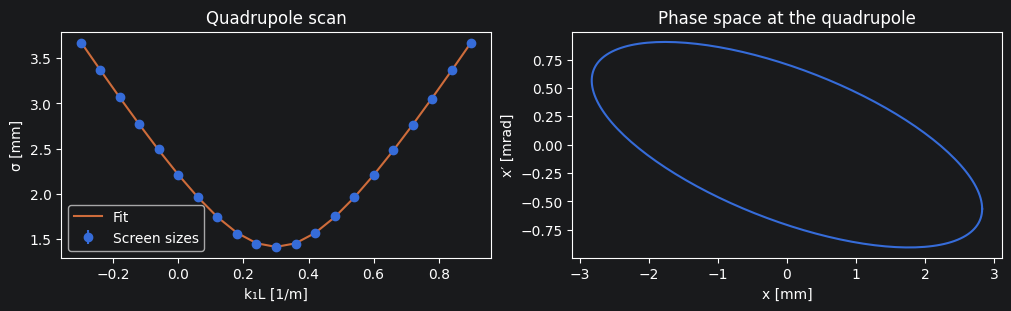

In [8]:
sigma_fit = np.sqrt(_sigma2(R11, R12, emittance, beta, alpha))
covariance_fit = beam_matrix(emittance, beta, alpha)
angle = np.linspace(0, 2 * np.pi, 200)
contour = np.linalg.cholesky(covariance_fit) @ np.array([np.cos(angle), np.sin(angle)])

fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
axes[0].errorbar(k, sigma_measured * 1e3, yerr=u_sigma * 1e3, fmt='o', label='Screen sizes')
axes[0].plot(k, sigma_fit * 1e3, label='Fit')
axes[0].set(xlabel='k₁L [1/m]', ylabel='σ [mm]', title='Quadrupole scan')
axes[0].legend()
axes[1].plot(contour[0] * 1e3, contour[1] * 1e3)
axes[1].set(xlabel='x [mm]', ylabel="x′ [mrad]", title='Phase space at the quadrupole')
plt.show()

## Three computing methods, one model, that is updated with measurements

The GUI offers three **Computing methods**.


| Method  | What predicts the scan | Extra fit parameters |
|---|---|---|
| Linear R-response model | $R_{11},R_{12},R_{33},R_{34}$ from four tracked test particles | no |
| RF-Track tracking | a tracked bunch of `nparticles` macroparticles | quadrupole strength, offset, roll, energy |
| Machine learning model  | a network trained on RF-Track tracking | strength; offset, roll and energy are tracked with RF-Track |

### The linear start: four test particles

For every quadrupole setting of the scan, `interface.get_R_matrix_scan()` sets the quadrupole in the model and tracks four single particles with RF-Track from the entrance of the scanned quadrupole to the last screen: $(x,x')=(1\,\mathrm{mm},0)$ and $(0,1\,\mathrm{mrad})$, and the same two in y. Their positions on each screen are directly the transfer-matrix elements,
$$x_1=R_{11}\cdot1\,\mathrm{mm},\qquad x_2=R_{12}\cdot1\,\mathrm{mrad}\quad(R_{12}\ \text{in m}),$$
and $R_{33},R_{34}$ from the y particles. This costs four particles instead of a beam, yet it uses the full model: thick quadrupoles, every element between the quadrupole and the screens, and the real screen positions. With these $R$ the fitter above (`_solve_plane`) gives $\varepsilon,\beta,\alpha$ for each plane. Every method starts here.


RF-Track, version 2.7.3

Copyright (C) 2016-2026 CERN, Geneva, Switzerland. All rights reserved.

Author and contact:
 Andrea Latina <andrea.latina@cern.ch>
 BE-ABP Group
 CERN
 CH-1211 GENEVA 23
 SWITZERLAND

This software is distributed under a CERN proprietary software
license in the hope that it will be useful, but WITHOUT ANY WARRANTY;
not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

See the COPYRIGHT and LICENSE files at the top-level directory of
the RF-Track download area: https://gitlab.cern.ch/rf-track

RF-Track was compiled with GSL-2.8 and fftw-3.3.11



[RF-Track] Could not check for updates.


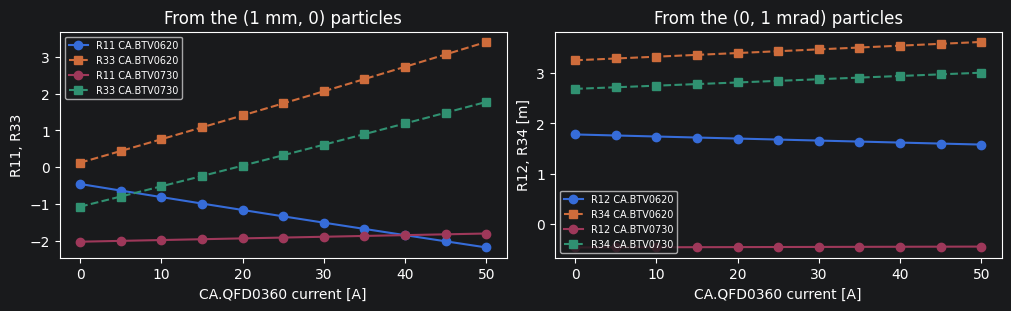

In [3]:
from machine_interfaces_clear.InterfaceCLEAR_RFTrack import InterfaceCLEAR_RFTrack
from emittance_measurement.EM_helpers.CheckLinearOptics import estimate_twiss_use_linear_optics_start

clear = InterfaceCLEAR_RFTrack()
quad, screens = 'CA.QFD0360', ['CA.BTV0620', 'CA.BTV0730']
currents = np.linspace(0, 50, 11)
R = clear.get_R_matrix_scan(quad, screens, currents)

fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for j, screen in enumerate(screens):
    axes[0].plot(currents, R['R11'][:, j], 'o-', label=f'R11 {screen}')
    axes[0].plot(currents, R['R33'][:, j], 's--', label=f'R33 {screen}')
    axes[1].plot(currents, R['R12'][:, j], 'o-', label=f'R12 {screen}')
    axes[1].plot(currents, R['R34'][:, j], 's--', label=f'R34 {screen}')
axes[0].set(xlabel=f'{quad} current [A]', ylabel='R11, R33', title='From the (1 mm, 0) particles')
axes[1].set(xlabel=f'{quad} current [A]', ylabel='R12, R34 [m]', title='From the (0, 1 mrad) particles')
for ax in axes:
    ax.legend(fontsize=7)
plt.show()

### Linear R-response model

`LinearResponseEngine` returns the linear start as the result: one weighted least-squares fit per plane, with the median size of each step and its shot-to-shot spread as the uncertainty. It needs no iterations and no trained model, but it cannot fit extra parameters; the GUI disables them in this mode.

Below, the "measured" scan is an RF-Track tracking of a known beam with 2 % noise added, and the linear start recovers that beam.


x: ε_n = 4.99 µm (true 5.0), β = 4.98 m (true 5.0), α = -3.51 (true -3.5), χ²_red = 0.31
y: ε_n = 4.94 µm (true 5.0), β = 9.97 m (true 10.0), α = -1.03 (true -1.0), χ²_red = 1.58


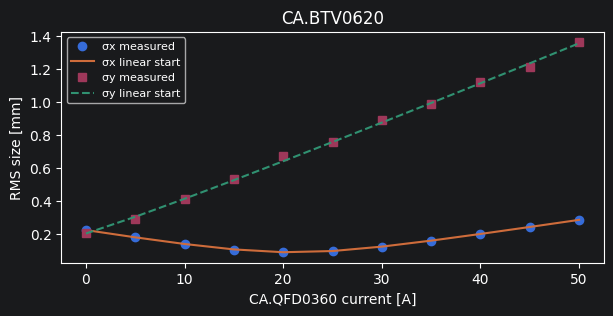

In [4]:
beam = dict(emit_x=5.0, emit_y=5.0, beta_x0=5.0, beta_y0=10.0, alpha_x0=-3.5, alpha_y0=-1.0)
sigx, sigy = clear.predict_emittance_scan_response(quad, screens, currents, **beam)
noise = np.random.default_rng(1)
sigx, sigy = sigx * (1 + noise.normal(0, 0.02, sigx.shape)), sigy * (1 + noise.normal(0, 0.02, sigy.shape))
beta_gamma = clear.get_beam_factors()[2]
start = estimate_twiss_use_linear_optics_start(clear, quad, screens, currents, sigx, sigy, 0.02 * sigx, 0.02 * sigy,
                                               np.isfinite(sigx), np.isfinite(sigy), beta_gamma)
for plane in 'xy':
    print(f"{plane}: ε_n = {start[f'emit_{plane}_norm']:.2f} µm (true {beam[f'emit_{plane}']}), "
          f"β = {start[f'beta_{plane}0']:.2f} m (true {beam[f'beta_{plane}0']}), "
          f"α = {start[f'alpha_{plane}0']:.2f} (true {beam[f'alpha_{plane}0']}), χ²_red = {start[f'reduced_chi2_{plane}']:.2f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(currents, sigx[:, 0], 'o', label='σx measured')
ax.plot(currents, np.sqrt(start['pred_x'][:, 0]), '-', label='σx linear start')
ax.plot(currents, sigy[:, 0], 's', label='σy measured')
ax.plot(currents, np.sqrt(start['pred_y'][:, 0]), '--', label='σy linear start')
ax.set(xlabel=f'{quad} current [A]', ylabel='RMS size [mm]', title=screens[0])
ax.legend(fontsize=8)
plt.show()

### RF-Track tracking

`RFTrackEngine` runs `Optimization._fit_6d`, which fits both planes together:

1. takes the median size of each step;
2. computes the linear start above. It is trusted for a plane if it lies inside the fit bounds, then the search is limited to ±15 % of the bound range around it, otherwise it starts from the middle of the bounds. $\chi^2_{red}>5$ usually means that the model optics differ from the machine (quadrupole currents, energy, calibration);
3. runs a bounded least-squares fit (`scipy.optimize.least_squares`). Every evaluation builds a bunch of `nparticles` macroparticles from the trial $\varepsilon,\beta,\alpha$ and tracks it with RF-Track from the quadrupole to the screens for every scan setting.
4. if the result sits at the edge of the ±15 % window, reopens the full bounds for that plane and fits once more;
5. estimates the parameter uncertainties from the Jacobian at the solution.

This method can fit **extra parameters**: a scale of the quadrupole strength, the transverse offset of the scanned quadrupole (from how the beam centroid on the screens moves with the current), its roll (from the x–y covariance $\sigma_{xy}$) and the beam energy, and is preferred, fast and most precise.


Largest difference between RF-Track tracking and the linear model: 0.35 %


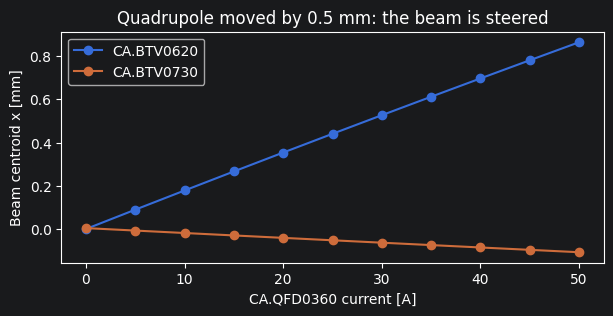

In [5]:
tracked_x, tracked_y = clear.predict_emittance_scan_response(quad, screens, currents, **beam)
linear_x = np.sqrt(_sigma2(R['R11'], R['R12'], beam['emit_x'] / beta_gamma, beam['beta_x0'], beam['alpha_x0']))
print(f'Largest difference between RF-Track tracking and the linear model: {100 * np.max(np.abs(linear_x / tracked_x - 1)):.2f} %')

offset = clear.predict_emittance_scan_response_full(quad, screens, currents, **beam, quad_dx0=0.5e-3, quad_dy0=0.0, quad_roll=0.0)
fig, ax = plt.subplots(figsize=(7, 3))
for j, screen in enumerate(screens):
    ax.plot(currents, offset['x_mean'][:, j], 'o-', label=screen)
ax.set(xlabel=f'{quad} current [A]', ylabel='Beam centroid x [mm]', title='Quadrupole moved by 0.5 mm: the beam is steered')
ax.legend()
plt.show()

### Machine learning model

`MLEngine` is the RF-Track method with one change: `MLInterface` wraps the interface and replaces `predict_emittance_scan_response` by the trained network, so every evaluation of step 3 takes microseconds instead of a tracking. Everything else still comes from RF-Track: the linear start uses the four test particles, offset, roll and energy fits call `predict_emittance_scan_response_full`, which falls back to RF-Track tracking, and the network itself is trained on RF-Track tracking data by `DatasetGenerator_ModelTrainer_EM_GUI.py`. It is reliable only inside the ranges it was trained on, and if no model exists for the machine and quadrupole the GUI uses RF-Track tracking instead.


## Choosing the scan range

The next cell repeats a 7-step scan 300 times for three ranges and compares the spread of the fitted emittance.

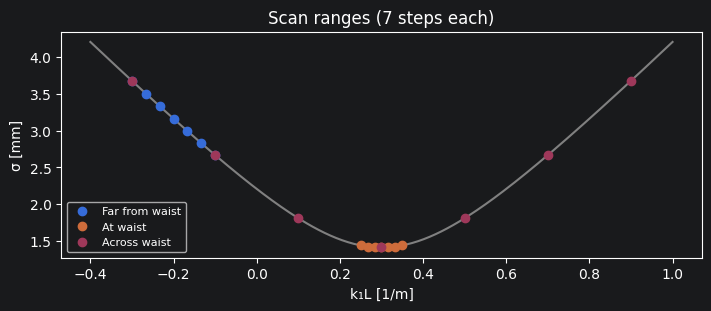

Far from waist   spread  43.58 %
At waist         spread  14.34 %
Across waist     spread   0.30 %


In [11]:
def spread(k_scan, repeats=300, u=8e-6):
    R11, R12 = 1.0 - L * k_scan, np.full(k_scan.size, L)
    sizes = scan_sizes(k_scan, truth, drift=L)
    values = []
    for _ in range(repeats):
        try:
            values.append(_solve_plane(R11, R12, sizes + rng.normal(0, u, k_scan.size), np.full(k_scan.size, u), np.ones(k_scan.size, bool))[0])
        except CheckLinearOpticsUnavailable:
            values.append(np.nan)
    values = np.array(values)
    return np.nanstd(values) / 2e-6, np.mean(np.isnan(values))

scans = {'Far from waist': np.linspace(-0.3, -0.1, 7), 'At waist': np.linspace(0.25, 0.35, 7), 'Across waist': np.linspace(-0.3, 0.9, 7)}
k_fine = np.linspace(-0.4, 1.0, 200)
fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
ax.plot(k_fine, scan_sizes(k_fine, truth, drift=L) * 1e3, color='gray')
results = {}
for label, k_scan in scans.items():
    results[label] = spread(k_scan)
    ax.plot(k_scan, scan_sizes(k_scan, truth, drift=L) * 1e3, 'o', label=label)
ax.set(xlabel='k₁L [1/m]', ylabel='σ [mm]', title='Scan ranges (7 steps each)')
ax.legend(fontsize=8)
plt.show()
for label, (relative, failed) in results.items():
    print(f'{label:16s} spread {100 * relative:6.2f} %')

A scan far from the waist sees only one side of the parabola, so the minimum $c$ and with it $\varepsilon$ are badly determined. A scan that only covers the waist sees the minimum but not the curvature. A scan that crosses the waist with enough range on both sides determines both.

## Choosing the parameters

| GUI field | Default | How to choose |
|---|---|---|
| Quadrupole | – | Upstream of the screens and strong enough to move the waist across the screen. |
| Screens | – | Downstream of the quadrupole. With **Steps = 0** the GUI uses several screens without scanning (multi-screen method), which needs at least three screens with different phase advance. |
| Current [A] range (min / max) | 0 / 150 | Must contain the waist on every screen, with similar range on both sides. **Current range per screen…** sets separate ranges. |
| Steps | 5 | At least 3; 7–15 show the parabola, reveal outliers and reduce the uncertainty.|
| Measurements per step | 10 | Averages beam sizes; $u(\bar\sigma)=s_\sigma/\sqrt N$. |
| Background shots | 10 | Median background image subtracted from every beam image (real machines only). |
| Computing method | – | Linear R-response model for a quick result with the six beam parameters; RF-Track tracking for the final fit and for extra parameters; Machine learning model for the same fit as RF-Track but faster, once a model is trained for this quadrupole. |
| Fit search bounds | interface values | Must contain the true values. |
| Fit quadrupole strength / offset / roll / energy | off | Each adds a parameter; enable only when the data constrain it (offset needs reliable centroids, roll needs σxy). |
| Delete chosen point | – | Excludes bad images from the fit while keeping the data. |